# Prédiction des mouvements du mid-price à partir d'un carnet d'ordres (LOBSTER)

**Actif :** Amazon (AMZN) — 21 juin 2012  
**Objectif :** prédire le mouvement futur du mid-price à partir de l'état du carnet et du flux d'événements.

Ce notebook suit un pipeline complet de Machine Learning : chargement, contrôle qualité, nettoyage, feature engineering, construction de la cible, séparation chronologique, validation croisée temporelle, entraînement, évaluation et conclusion.

> **Important — unité de temps :** chaque ligne correspond à un événement de marché, pas à une seconde fixe. L'horizon `HORIZON = 10` signifie donc « les 10 prochains événements ». La durée réelle correspondante varie dans le temps.

> **Important — interprétation :** il s'agit d'un exercice de prédiction statistique, pas d'une stratégie de trading directement exploitable. Les coûts, la latence, la profondeur réellement exécutable et le slippage ne sont pas modélisés ici.


## 1. Imports et paramètres

In [1]:
# Si nécessaire, décommentez la ligne suivante :
# %pip install pandas numpy matplotlib seaborn scikit-learn

import warnings
warnings.filterwarnings("ignore")

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.base import clone
from sklearn.dummy import DummyClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import TimeSeriesSplit, cross_validate
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, precision_recall_fscore_support,
    classification_report, confusion_matrix, ConfusionMatrixDisplay,
    f1_score
)

RANDOM_STATE = 42

# Les deux CSV doivent être placés dans le même dossier que ce notebook.
MESSAGE_PATH = Path("AMZN_2012-06-21_34200000_57600000_message_10.csv")
ORDERBOOK_PATH = Path("AMZN_2012-06-21_34200000_57600000_orderbook_10.csv")

# Paramètres du problème
N_LEVELS = 10
HORIZON = 10                  # nombre d'événements futurs
TICK_SIZE_RAW = 1           # 1 tick = 0.01 USD si les prix sont codés en 1/10 000 USD
PRICE_SCALE = 10_000          # conversion du prix LOBSTER en dollars
THRESHOLD_RAW = TICK_SIZE_RAW # seuil de mouvement significatif : un tick


## 2. Chargement des données

Les deux fichiers LOBSTER sont alignés ligne par ligne : la ligne *i* du fichier `message` décrit l'événement qui a produit l'état du carnet de la ligne *i* du fichier `orderbook`.

Le fichier `message` contient 6 colonnes : temps, type d'événement, identifiant d'ordre, taille, prix et direction. Le fichier `orderbook` contient 4 colonnes par niveau : prix ask, taille ask, prix bid, taille bid.

In [2]:
message_cols = ["time", "event_type", "order_id", "size", "event_price", "direction"]

message = pd.read_csv(MESSAGE_PATH, header=None, names=message_cols)

ob_cols = []
for level in range(1, N_LEVELS + 1):
    ob_cols += [
        f"ask_price_{level}", f"ask_size_{level}",
        f"bid_price_{level}", f"bid_size_{level}"
    ]

orderbook = pd.read_csv(ORDERBOOK_PATH, header=None, names=ob_cols)

print("Message :", message.shape)
print("Orderbook :", orderbook.shape)

assert len(message) == len(orderbook), "Les deux fichiers ne sont pas alignés en nombre de lignes."

df = pd.concat([message, orderbook], axis=1)
display(df.head())


Message : (269748, 6)
Orderbook : (269748, 40)


,time,event_type,order_id,size,event_price,direction,ask_price_1,ask_size_1,bid_price_1,bid_size_1,...,bid_price_8,bid_size_8,ask_price_9,ask_size_9,bid_price_9,bid_size_9,ask_price_10,ask_size_10,bid_price_10,bid_size_10
0,34200.017460,5,0,1,2238200,-1,2239500,100,2231800,100,...,2202500,5000,2294300,100,2202000,100,2298000,100,2189700,100
1,34200.189608,1,11885113,21,2238100,1,2239500,100,2238100,21,...,2204000,100,2294300,100,2202500,5000,2298000,100,2202000,100
2,34200.189608,1,3911376,20,2239600,-1,2239500,100,2238100,21,...,2204000,100,2267700,100,2202500,5000,2294300,100,2202000,100
3,34200.189608,1,11534792,100,2237500,1,2239500,100,2238100,21,...,2213000,4000,2267700,100,2204000,100,2294300,100,2202500,5000
4,34200.189608,1,1365373,13,2240000,-1,2239500,100,2238100,21,...,2213000,4000,2267700,100,2204000,100,2294300,100,2202500,5000


## 3. Exploration et contrôles de cohérence

In [3]:
print("Dimensions :", df.shape)
print("\nTypes d'événements :")
display(df["event_type"].value_counts().sort_index().rename("count").to_frame())

print("\nValeurs manquantes :")
display(df.isna().sum().loc[lambda x: x > 0])

print("\nRésumé des messages :")
display(df[["time", "event_type", "size", "event_price", "direction"]].describe())

print("\nTemps croissant :", df["time"].is_monotonic_increasing)
print("Nombre de timestamps dupliqués :", df["time"].duplicated().sum())


Dimensions : (269748, 46)

Types d'événements :


,count
event_type,
1,131954
2,2917
3,123458
4,8974
5,2445



Valeurs manquantes :


Series([], dtype: int64)


Résumé des messages :


,time,event_type,size,event_price,direction
count,269748.000000,269748.000000,269748.000000,2.697480e+05,269748.000000
mean,46236.162475,2.062232,96.870505,2.227204e+06,-0.033587
std,7252.195869,1.075934,168.846801,1.406809e+04,0.999438
min,34200.017460,1.000000,1.000000,2.204000e+06,-1.000000
25%,39632.683709,1.000000,21.000000,2.213000e+06,-1.000000
50%,45755.206530,3.000000,100.000000,2.226600e+06,-1.000000
75%,53220.267215,3.000000,100.000000,2.239100e+06,1.000000
max,57599.959360,5.000000,33570.000000,2.276000e+06,1.000000



Temps croissant : True
Nombre de timestamps dupliqués : 8483


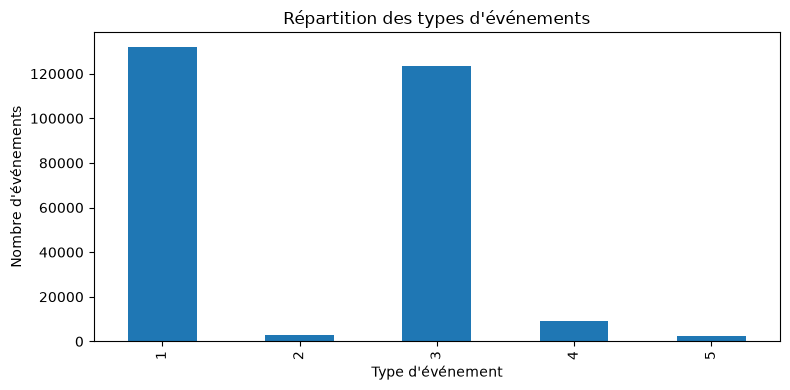

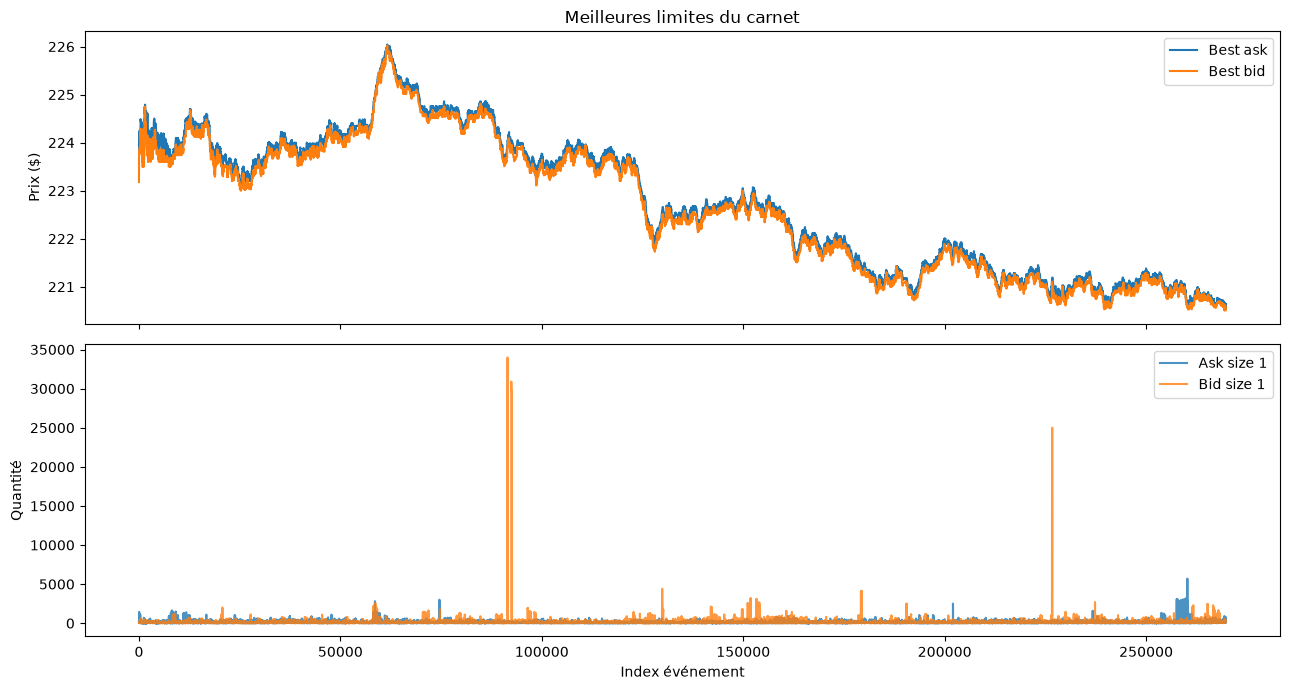

In [4]:
# Visualisation de la fréquence des types d'événements
ax = df["event_type"].value_counts().sort_index().plot(kind="bar", figsize=(8, 4))
ax.set_title("Répartition des types d'événements")
ax.set_xlabel("Type d'événement")
ax.set_ylabel("Nombre d'événements")
plt.tight_layout()
plt.show()

# Prix et tailles au meilleur bid / ask
fig, axes = plt.subplots(2, 1, figsize=(13, 7), sharex=True)
axes[0].plot(df.index, df["ask_price_1"] / PRICE_SCALE, label="Best ask")
axes[0].plot(df.index, df["bid_price_1"] / PRICE_SCALE, label="Best bid")
axes[0].set_ylabel("Prix ($)")
axes[0].legend()
axes[0].set_title("Meilleures limites du carnet")
axes[1].plot(df.index, df["ask_size_1"], label="Ask size 1", alpha=.8)
axes[1].plot(df.index, df["bid_size_1"], label="Bid size 1", alpha=.8)
axes[1].set_ylabel("Quantité")
axes[1].set_xlabel("Index événement")
axes[1].legend()
plt.tight_layout()
plt.show()


## 4. Nettoyage des données

LOBSTER utilise des valeurs sentinelles pour signaler les niveaux inexistants : prix ask `9999999999` et prix bid `-9999999999`, avec une taille nulle. Ces valeurs ne sont pas des prix de marché.

On les convertit en valeurs manquantes. On vérifie ensuite la validité du meilleur bid et du meilleur ask. Les événements de type 7 correspondent à des messages de statut / interruption : ils sont exclus. On ne supprime **pas** les lignes simplement parce que deux états consécutifs du carnet sont identiques.

In [5]:
df = df.copy()

# Remplacer les prix sentinelles par NaN
for level in range(1, N_LEVELS + 1):
    ap, bp = f"ask_price_{level}", f"bid_price_{level}"
    df.loc[df[ap] >= 9_999_999_999, ap] = np.nan
    df.loc[df[bp] <= -9_999_999_999, bp] = np.nan

# Contrôles de validité du meilleur niveau
valid_best = (
    df["ask_price_1"].notna()
    & df["bid_price_1"].notna()
    & (df["ask_size_1"] >= 0)
    & (df["bid_size_1"] >= 0)
    & (df["ask_price_1"] > df["bid_price_1"])
)

print("États avec meilleur bid/ask valide :", valid_best.mean().round(4))
print("Événements de type 7 :", (df["event_type"] == 7).sum())

# Les types 7 marquent une rupture de séquence : on crée un identifiant de segment.
# Les labels ne pourront pas traverser une telle rupture.
df["segment_id"] = (df["event_type"] == 7).cumsum()

# On retire les messages de statut et les états invalides.
df = df.loc[(df["event_type"] != 7) & valid_best].copy()

# Vérification de l'ordre chronologique après nettoyage
df = df.sort_values("time").copy()
df.reset_index(drop=True, inplace=True)

print("Dimensions après nettoyage :", df.shape)


États avec meilleur bid/ask valide : 1.0
Événements de type 7 : 0
Dimensions après nettoyage : (269748, 47)


## 5. Construction des variables explicatives (features)

Toutes les features doivent être calculables avec les informations disponibles à l'instant \(t\). Les variables sont construites à partir du carnet courant et des événements passés.

On utilise notamment :
- spread et mid-price ;
- imbalance des quantités au meilleur niveau et sur les 5 premiers niveaux ;
- microprice et écart microprice-midprice ;
- profondeur cumulée ;
- rendements et volatilité historiques ;
- variations d'OBI ;
- Order Flow Imbalance (OFI) ;
- statistiques glissantes du flux d'événements.

**Convention importante :** `direction` dans le fichier message décrit le côté de l'ordre associé à l'événement dans la convention LOBSTER. Pour les exécutions, ce n'est pas nécessairement le côté de l'agent agressif. On utilise donc ici les volumes signés comme indicateur de flux du côté de l'ordre référencé, sans les interpréter comme des achats/ventes agressifs.

In [6]:
# Prix et tailles du meilleur niveau
df["mid_price"] = (df["ask_price_1"] + df["bid_price_1"]) / 2
df["spread"] = df["ask_price_1"] - df["bid_price_1"]

# Microprice : pondération du prix par la quantité opposée
denom = df["bid_size_1"] + df["ask_size_1"]
df["microprice"] = np.where(
    denom > 0,
    (df["ask_price_1"] * df["bid_size_1"]
     + df["bid_price_1"] * df["ask_size_1"]) / denom,
    df["mid_price"]
)
df["micro_minus_mid"] = df["microprice"] - df["mid_price"]

# Imbalance des quantités sur différents niveaux
def order_imbalance(bid_sizes, ask_sizes):
    bid_depth = bid_sizes.sum(axis=1)
    ask_depth = ask_sizes.sum(axis=1)
    total = bid_depth + ask_depth
    return np.where(total > 0, (bid_depth - ask_depth) / total, 0.0)

bid_cols_1 = [f"bid_size_{i}" for i in range(1, 2)]
ask_cols_1 = [f"ask_size_{i}" for i in range(1, 2)]
bid_cols_5 = [f"bid_size_{i}" for i in range(1, 6)]
ask_cols_5 = [f"ask_size_{i}" for i in range(1, 6)]

df["obi_l1"] = order_imbalance(df[bid_cols_1], df[ask_cols_1])
df["obi_l5"] = order_imbalance(df[bid_cols_5], df[ask_cols_5])

# OBI pondéré : les niveaux proches du meilleur prix ont davantage de poids
weights = 1 / np.arange(1, 6)
weighted_bid = df[bid_cols_5].to_numpy() @ weights
weighted_ask = df[ask_cols_5].to_numpy() @ weights
weighted_total = weighted_bid + weighted_ask
df["obi_weighted"] = np.divide(
    weighted_bid - weighted_ask, weighted_total,
    out=np.zeros(len(df), dtype=float), where=weighted_total > 0
)

df["bid_depth_l5"] = df[bid_cols_5].sum(axis=1)
df["ask_depth_l5"] = df[ask_cols_5].sum(axis=1)

# Dynamiques du mid-price : uniquement passé et présent
df["mid_return_1"] = df["mid_price"].diff(1)
df["mid_return_5"] = df["mid_price"].diff(5)
df["mid_volatility_10"] = df["mid_return_1"].rolling(10, min_periods=5).std()

df["obi_change"] = df["obi_l1"].diff(1)
df["microprice_change"] = df["microprice"].diff(1)

# OFI au meilleur bid / ask (formulation événementielle classique)
pb = df["bid_price_1"]
qb = df["bid_size_1"]
pa = df["ask_price_1"]
qa = df["ask_size_1"]

pb_prev, qb_prev = pb.shift(1), qb.shift(1)
pa_prev, qa_prev = pa.shift(1), qa.shift(1)

bid_flow = (
    (pb >= pb_prev).astype(float) * qb
    - (pb <= pb_prev).astype(float) * qb_prev
)
ask_flow = (
    -(pa <= pa_prev).astype(float) * qa
    + (pa >= pa_prev).astype(float) * qa_prev
)
df["ofi"] = bid_flow + ask_flow

# Variables de flux issues du fichier message
df["is_submission"] = (df["event_type"] == 1).astype(int)
df["is_cancellation"] = df["event_type"].isin([2, 3]).astype(int)
df["is_trade"] = df["event_type"].isin([4, 5]).astype(int)

df["submission_count_10"] = df["is_submission"].rolling(10).sum()
df["cancellation_volume_10"] = (
    df["size"].where(df["event_type"].isin([2, 3]), 0).rolling(10).sum()
)
df["trade_volume_10"] = (
    df["size"].where(df["event_type"].isin([4, 5]), 0).rolling(10).sum()
)

# Flux signé selon le côté de l'ordre référencé par le message.
df["signed_event_volume"] = (
    df["size"].fillna(0) * df["direction"].fillna(0)
    * df["event_type"].isin([1, 2, 3, 4, 5]).astype(int)
)
signed_sum = df["signed_event_volume"].rolling(10).sum()
absolute_sum = (
    df["size"].fillna(0)
    .where(df["event_type"].isin([1, 2, 3, 4, 5]), 0)
    .rolling(10).sum()
)
df["signed_flow_imbalance_10"] = np.divide(
    signed_sum, absolute_sum,
    out=np.zeros(len(df), dtype=float), where=absolute_sum.to_numpy() > 0
)

display(df[[
    "mid_price", "spread", "obi_l1", "obi_l5", "micro_minus_mid",
    "mid_return_1", "ofi", "trade_volume_10"
]].head(15))


,mid_price,spread,obi_l1,obi_l5,micro_minus_mid,mid_return_1,ofi,trade_volume_10
0,2235650.0,7700.0,0.000000,-0.353202,0.000000,NaN,NaN,NaN
1,2238800.0,1400.0,-0.652893,-0.424566,-457.024793,3150.0,21.0,NaN
2,2238800.0,1400.0,-0.652893,-0.112255,-457.024793,0.0,0.0,NaN
3,2238800.0,1400.0,-0.652893,-0.017908,-457.024793,0.0,0.0,NaN
4,2238800.0,1400.0,-0.652893,-0.029795,-457.024793,0.0,0.0,NaN
5,2238800.0,1400.0,-0.652893,-0.133197,-457.024793,0.0,0.0,NaN
6,2238800.0,1400.0,-0.652893,-0.213755,-457.024793,0.0,0.0,NaN
7,2238800.0,1400.0,-0.652893,-0.465769,-457.024793,0.0,0.0,NaN
8,2238800.0,1400.0,-0.652893,-0.468156,-457.024793,0.0,0.0,NaN
9,2238800.0,1400.0,-0.652893,-0.468156,-457.024793,0.0,0.0,1.0


## 6. Construction de la variable cible

On cherche à prédire le mouvement du mid-price dans les `HORIZON` prochains événements.

La cible est une classification à trois classes :
- `-1` : baisse d'au moins un tick ;
- `0` : variation comprise entre moins un tick et plus un tick ;
- `1` : hausse d'au moins un tick.

Le seuil est fixé à un tick de cotation. Pour les actions américaines cotées au-dessus de 1 dollar, un tick vaut généralement 0,01 USD. Avec l'encodage LOBSTER utilisé ici, cela correspond à 100 unités de prix brutes (à vérifier selon le format du fichier / l'instrument).

Les lignes dont la cible future n'est pas disponible sont supprimées. On vérifie aussi que la cible ne traverse pas un événement de statut / une rupture de segment.

In [7]:
# Le mid-price futur est défini par un décalage vers le passé du futur :
df["future_mid_price"] = df["mid_price"].shift(-HORIZON)
df["future_segment_id"] = df["segment_id"].shift(-HORIZON)

df["future_change"] = df["future_mid_price"] - df["mid_price"]

same_segment = df["segment_id"] == df["future_segment_id"]
df["target"] = np.select(
    [
        df["future_change"] > THRESHOLD_RAW,
        df["future_change"] < -THRESHOLD_RAW
    ],
    [1, -1],
    default=0
)

# Les observations invalides ou dont le futur traverse une rupture sont exclues.
df.loc[~same_segment, "target"] = np.nan
df.loc[df["future_mid_price"].isna(), "target"] = np.nan

print("Distribution brute de la cible :")
display(df["target"].value_counts(dropna=False).sort_index().to_frame("count"))

print("\nDistribution en pourcentage :")
display((df["target"].value_counts(normalize=True).sort_index() * 100).round(2).to_frame("%"))


Distribution brute de la cible :


,count
target,
-1.0,68510
0.0,136137
1.0,65091
NaN,10



Distribution en pourcentage :


,%
target,
-1.0,25.40
0.0,50.47
1.0,24.13


## 7. Dataset final et contrôle des features

In [8]:
FEATURES = [
    "spread",
    "micro_minus_mid",
    "obi_l1",
    "obi_l5",
    "obi_weighted",
    "bid_depth_l5",
    "ask_depth_l5",
    "mid_return_1",
    "mid_return_5",
    "mid_volatility_10",
    "obi_change",
    "microprice_change",
    "ofi",
    "submission_count_10",
    "cancellation_volume_10",
    "trade_volume_10",
    "signed_flow_imbalance_10"
]

model_data = df[FEATURES + ["target", "time"]].replace([np.inf, -np.inf], np.nan)
model_data = model_data.dropna(subset=["target"]).copy()

# Les NaN de features sont conservés : ils seront imputés dans le Pipeline,
# mais on supprime les observations entièrement dépourvues de features.
model_data = model_data.dropna(subset=FEATURES, how="all").reset_index(drop=True)
model_data["target"] = model_data["target"].astype(int)

X = model_data[FEATURES]
y = model_data["target"]

print("Nombre d'observations :", len(model_data))
print("Nombre de features :", len(FEATURES))
print("Valeurs manquantes par feature :")
display(X.isna().sum().to_frame("missing"))
print("Distribution cible :")
display(y.value_counts(normalize=True).sort_index().mul(100).round(2).to_frame("percentage"))


Nombre d'observations : 269738
Nombre de features : 17
Valeurs manquantes par feature :


,missing
spread,0
micro_minus_mid,0
obi_l1,0
obi_l5,0
obi_weighted,0
bid_depth_l5,0
ask_depth_l5,0
mid_return_1,1
mid_return_5,5
mid_volatility_10,5


Distribution cible :


,percentage
target,
-1,25.40
0,50.47
1,24.13


## 8. Séparation chronologique train / validation / test

On ne mélange pas aléatoirement les événements : cela ferait apprendre au modèle sur des observations futures par rapport à certaines observations d'entraînement.

On conserve l'ordre chronologique :
- 70 % des observations pour l'entraînement ;
- 15 % pour la validation ;
- 15 % pour le test final.

On applique un *purge* de `HORIZON` observations entre les blocs pour limiter le chevauchement des fenêtres de cible. Le test final ne sera utilisé qu'une fois les choix de modèles effectués.

In [9]:
n = len(model_data)
train_end = int(0.70 * n)
valid_end = int(0.85 * n)
purge = HORIZON

train_idx = np.arange(0, max(0, train_end - purge))
valid_idx = np.arange(train_end, max(train_end, valid_end - purge))
test_idx = np.arange(valid_end, n)

X_train, y_train = X.iloc[train_idx], y.iloc[train_idx]
X_valid, y_valid = X.iloc[valid_idx], y.iloc[valid_idx]
X_test, y_test = X.iloc[test_idx], y.iloc[test_idx]

print("Train :", X_train.shape, model_data.iloc[train_idx]["time"].min(), "->", model_data.iloc[train_idx]["time"].max())
print("Valid :", X_valid.shape, model_data.iloc[valid_idx]["time"].min(), "->", model_data.iloc[valid_idx]["time"].max())
print("Test  :", X_test.shape, model_data.iloc[test_idx]["time"].min(), "->", model_data.iloc[test_idx]["time"].max())

assert model_data.iloc[train_idx]["time"].max() < model_data.iloc[valid_idx]["time"].min()
assert model_data.iloc[valid_idx]["time"].max() < model_data.iloc[test_idx]["time"].min()


Train : (188806, 17) 34200.017459617 -> 51730.831993468
Valid : (40451, 17) 51732.022655004 -> 55340.069477528
Test  : (40461, 17) 55341.356838306 -> 57599.539471934


## 9. Baseline et modèles

On compare trois approches :
1. **Baseline majoritaire** : prédit toujours la classe la plus fréquente. Elle permet de vérifier que les modèles apprennent réellement quelque chose.
2. **Régression logistique multinomiale** : modèle linéaire interprétable. La standardisation et l'imputation sont intégrées au pipeline pour éviter toute fuite d'information.
3. **Random Forest** : modèle non linéaire capable de capter des interactions entre variables.

On ne réalise pas de SMOTE : sur des observations séquentielles de carnet d'ordres, des observations synthétiques peuvent ne pas correspondre à des états de marché plausibles.

In [10]:
models = {
    "Majority baseline": DummyClassifier(strategy="most_frequent"),
    "Logistic Regression": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(
            max_iter=2000,
            class_weight="balanced",
            random_state=RANDOM_STATE
        ))
    ]),
    "Random Forest": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", RandomForestClassifier(
            n_estimators=300,
            max_depth=12,
            min_samples_leaf=20,
            class_weight="balanced_subsample",
            n_jobs=-1,
            random_state=RANDOM_STATE
        ))
    ])
}


## 10. Validation croisée temporelle sur le train

La validation croisée utilise `TimeSeriesSplit` : chaque fold entraîne le modèle sur le passé et valide sur un bloc chronologiquement ultérieur. Les métriques principales sont le **macro F1-score** (même poids pour chaque classe) et la **balanced accuracy** (moyenne des rappels par classe).

La validation croisée est réalisée uniquement sur le bloc train. Le bloc validation séparé sert ensuite à comparer les modèles avant le test final.

In [11]:
tscv = TimeSeriesSplit(n_splits=5)

scoring = {
    "accuracy": "accuracy",
    "balanced_accuracy": "balanced_accuracy",
    "macro_f1": "f1_macro"
}

cv_rows = []
for name, estimator in models.items():
    scores = cross_validate(
        estimator, X_train, y_train,
        cv=tscv, scoring=scoring,
        n_jobs=None, error_score="raise"
    )
    cv_rows.append({
        "Model": name,
        "CV Accuracy": scores["test_accuracy"].mean(),
        "CV Balanced Accuracy": scores["test_balanced_accuracy"].mean(),
        "CV Macro F1": scores["test_macro_f1"].mean(),
        "CV Macro F1 Std": scores["test_macro_f1"].std()
    })

cv_results = pd.DataFrame(cv_rows).sort_values("CV Macro F1", ascending=False)
display(cv_results.round(4))


,Model,CV Accuracy,CV Balanced Accuracy,CV Macro F1,CV Macro F1 Std
2,Random Forest,0.4562,0.4274,0.4208,0.0105
1,Logistic Regression,0.4178,0.4004,0.3864,0.0162
0,Majority baseline,0.5080,0.3333,0.2242,0.0134


## 11. Comparaison sur le bloc de validation

In [12]:
validation_rows = []
fitted_models = {}

for name, estimator in models.items():
    fitted = clone(estimator)
    fitted.fit(X_train, y_train)
    pred = fitted.predict(X_valid)
    fitted_models[name] = fitted

    validation_rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_valid, pred),
        "Balanced accuracy": balanced_accuracy_score(y_valid, pred),
        "Macro F1": f1_score(y_valid, pred, average="macro", zero_division=0)
    })

validation_results = pd.DataFrame(validation_rows).sort_values("Macro F1", ascending=False)
display(validation_results.round(4))

best_name = validation_results.iloc[0]["Model"]
print("Modèle sélectionné sur validation :", best_name)


,Model,Accuracy,Balanced accuracy,Macro F1
2,Random Forest,0.4449,0.4354,0.4217
1,Logistic Regression,0.3941,0.4147,0.3865
0,Majority baseline,0.5439,0.3333,0.2349


Modèle sélectionné sur validation : Random Forest


## 12. Analyse détaillée du modèle sélectionné sur validation

              precision    recall  f1-score   support

 Baisse (-1)       0.33      0.44      0.38      9658
  Neutre (0)       0.61      0.46      0.53     22000
 Hausse (+1)       0.33      0.41      0.36      8793

    accuracy                           0.44     40451
   macro avg       0.42      0.44      0.42     40451
weighted avg       0.48      0.44      0.45     40451



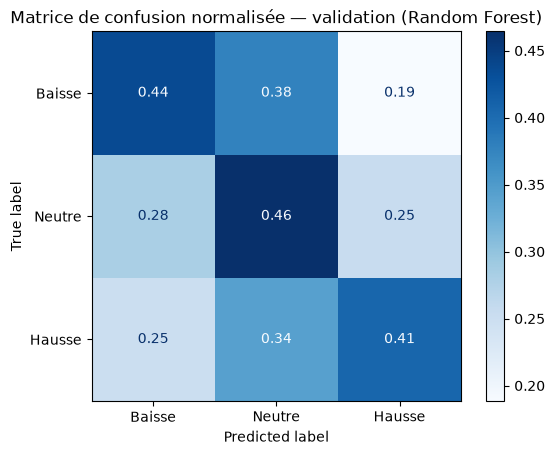

In [13]:
valid_pred = fitted_models[best_name].predict(X_valid)

print(classification_report(
    y_valid, valid_pred,
    labels=[-1, 0, 1],
    target_names=["Baisse (-1)", "Neutre (0)", "Hausse (+1)"],
    zero_division=0
))

cm = confusion_matrix(y_valid, valid_pred, labels=[-1, 0, 1], normalize="true")
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Baisse", "Neutre", "Hausse"]
)
disp.plot(cmap="Blues", values_format=".2f")
plt.title(f"Matrice de confusion normalisée — validation ({best_name})")
plt.show()


## 13. Entraînement final et évaluation sur le test

Après sélection sur validation, on réentraîne le modèle choisi sur train + validation, puis on évalue une seule fois sur le test. Le test représente la partie chronologiquement la plus récente des données.

La performance du test est la meilleure estimation disponible de la capacité de généralisation sur cette journée, mais une seule journée ne permet pas de conclure à une robustesse inter-journalière.

In [14]:
X_train_valid = pd.concat([X_train, X_valid], axis=0)
y_train_valid = pd.concat([y_train, y_valid], axis=0)

final_model = clone(models[best_name])
final_model.fit(X_train_valid, y_train_valid)
test_pred = final_model.predict(X_test)

test_accuracy = accuracy_score(y_test, test_pred)
test_balanced_accuracy = balanced_accuracy_score(y_test, test_pred)
test_macro_f1 = f1_score(y_test, test_pred, average="macro", zero_division=0)

print(f"Modèle final : {best_name}")
print(f"Accuracy          : {test_accuracy:.4f}")
print(f"Balanced accuracy : {test_balanced_accuracy:.4f}")
print(f"Macro F1          : {test_macro_f1:.4f}")

print("\nRapport de classification :")
print(classification_report(
    y_test, test_pred,
    labels=[-1, 0, 1],
    target_names=["Baisse (-1)", "Neutre (0)", "Hausse (+1)"],
    zero_division=0
))


Modèle final : Random Forest
Accuracy          : 0.4278
Balanced accuracy : 0.4283
Macro F1          : 0.4152

Rapport de classification :
              precision    recall  f1-score   support

 Baisse (-1)       0.33      0.44      0.38      9817
  Neutre (0)       0.58      0.43      0.49     20719
 Hausse (+1)       0.34      0.42      0.38      9925

    accuracy                           0.43     40461
   macro avg       0.42      0.43      0.42     40461
weighted avg       0.46      0.43      0.44     40461



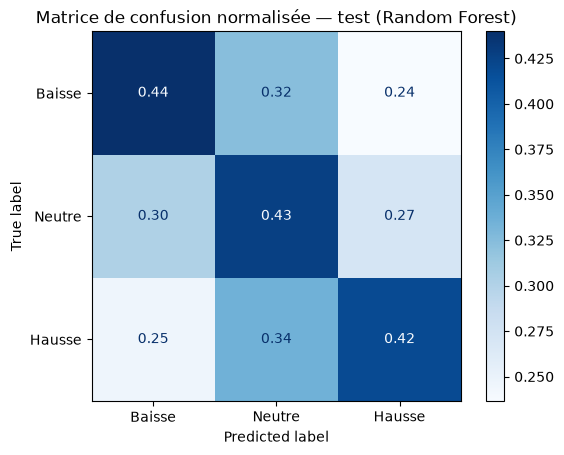

,Model,Accuracy,Balanced accuracy,Macro F1
0,Majority baseline,0.5121,0.3333,0.2258
1,Random Forest,0.4278,0.4283,0.4152


In [15]:
cm_test = confusion_matrix(y_test, test_pred, labels=[-1, 0, 1], normalize="true")
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_test,
    display_labels=["Baisse", "Neutre", "Hausse"]
)
disp.plot(cmap="Blues", values_format=".2f")
plt.title(f"Matrice de confusion normalisée — test ({best_name})")
plt.show()

# Comparaison au classifieur majoritaire sur le test
majority_class = y_train_valid.value_counts().idxmax()
baseline_pred = np.full(len(y_test), majority_class)

comparison = pd.DataFrame({
    "Model": ["Majority baseline", best_name],
    "Accuracy": [
        accuracy_score(y_test, baseline_pred),
        accuracy_score(y_test, test_pred)
    ],
    "Balanced accuracy": [
        balanced_accuracy_score(y_test, baseline_pred),
        balanced_accuracy_score(y_test, test_pred)
    ],
    "Macro F1": [
        f1_score(y_test, baseline_pred, average="macro", zero_division=0),
        f1_score(y_test, test_pred, average="macro", zero_division=0)
    ]
})
display(comparison.round(4))


In [19]:
from sklearn.metrics import classification_report

# Classification report - Majority baseline
print("===== MAJORITY BASELINE =====")
print(classification_report(
    y_test,
    baseline_pred,
    labels=[-1, 0, 1],
    target_names=["Baisse", "Neutre", "Hausse"],
    zero_division=0
))

# Classification report - Random Forest
print(f"===== {best_name.upper()} =====")
print(classification_report(
    y_test,
    test_pred,
    labels=[-1, 0, 1],
    target_names=["Baisse", "Neutre", "Hausse"],
    zero_division=0
))

===== MAJORITY BASELINE =====
              precision    recall  f1-score   support

      Baisse       0.00      0.00      0.00      9817
      Neutre       0.51      1.00      0.68     20719
      Hausse       0.00      0.00      0.00      9925

    accuracy                           0.51     40461
   macro avg       0.17      0.33      0.23     40461
weighted avg       0.26      0.51      0.35     40461

===== RANDOM FOREST =====
              precision    recall  f1-score   support

      Baisse       0.33      0.44      0.38      9817
      Neutre       0.58      0.43      0.49     20719
      Hausse       0.34      0.42      0.38      9925

    accuracy                           0.43     40461
   macro avg       0.42      0.43      0.42     40461
weighted avg       0.46      0.43      0.44     40461



## 14. Importance des variables

L'importance dépend du modèle sélectionné. Pour une régression logistique, on examine les coefficients en valeur absolue (après standardisation). Pour une Random Forest, on examine l'importance par diminution d'impureté. Cette dernière peut favoriser les variables continues ou présentant de nombreuses valeurs distinctes ; elle ne prouve pas une relation causale.

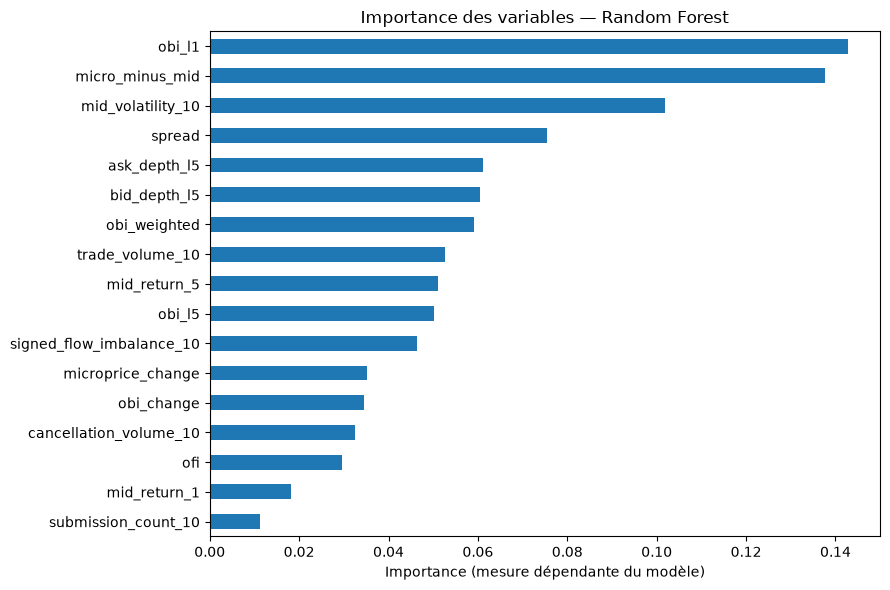

,importance
obi_l1,0.142815
micro_minus_mid,0.137665
mid_volatility_10,0.101927
spread,0.075548
ask_depth_l5,0.061248
bid_depth_l5,0.060369
obi_weighted,0.059072
trade_volume_10,0.052695
mid_return_5,0.051125
obi_l5,0.050285


In [16]:
if best_name == "Logistic Regression":
    model_step = final_model.named_steps["model"]
    importance_values = np.mean(np.abs(model_step.coef_), axis=0)
elif best_name == "Random Forest":
    model_step = final_model.named_steps["model"]
    importance_values = model_step.feature_importances_
else:
    importance_values = None
    print("La baseline majoritaire ne possède pas d'importance de variables.")

if importance_values is not None:
    importance = pd.Series(importance_values, index=FEATURES).sort_values()
    plt.figure(figsize=(9, 6))
    importance.plot(kind="barh")
    plt.title(f"Importance des variables — {best_name}")
    plt.xlabel("Importance (mesure dépendante du modèle)")
    plt.tight_layout()
    plt.show()

    display(importance.sort_values(ascending=False).to_frame("importance").head(10))


## 15. Analyse temporelle et limites

Durée entre t et t+HORIZON (secondes) :


,seconds
count,269738.000000
mean,0.867492
std,1.437190
min,0.000000
10%,0.004112
25%,0.031248
50%,0.345290
75%,1.083988
90%,2.373047
max,25.620290


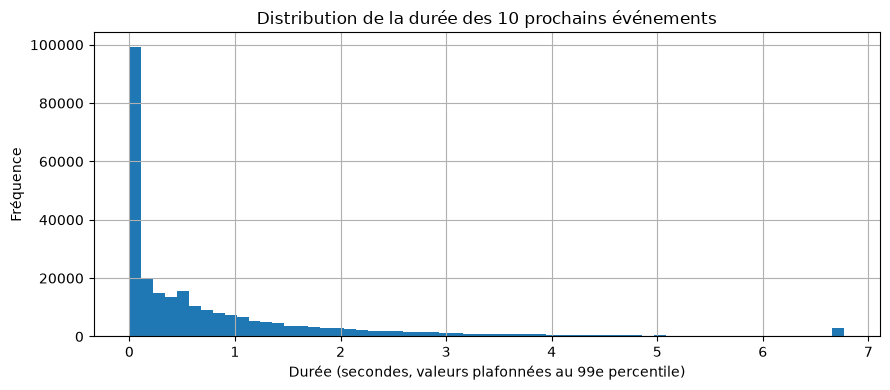

In [17]:
# Durée réelle associée à l'horizon en nombre d'événements
# On estime la durée entre t et t+HORIZON sur les timestamps d'origine.
time_series = df["time"].reset_index(drop=True)
elapsed = time_series.shift(-HORIZON) - time_series
elapsed = elapsed.dropna()

print("Durée entre t et t+HORIZON (secondes) :")
display(elapsed.describe(percentiles=[.1, .25, .5, .75, .9]).to_frame("seconds"))

plt.figure(figsize=(9, 4))
elapsed.clip(upper=elapsed.quantile(.99)).hist(bins=60)
plt.title(f"Distribution de la durée des {HORIZON} prochains événements")
plt.xlabel("Durée (secondes, valeurs plafonnées au 99e percentile)")
plt.ylabel("Fréquence")
plt.tight_layout()
plt.show()


### Limites méthodologiques à discuter

1. **Une seule journée :** le modèle peut apprendre des caractéristiques propres au 21 juin 2012. Il faut répéter l'expérience sur plusieurs jours, puis réserver des journées entières pour le test.
2. **Temps événementiel :** dix événements peuvent durer quelques millisecondes ou beaucoup plus longtemps. Il serait utile de comparer plusieurs horizons (par exemple 10, 50 et 100 événements) et un horizon en temps calendaire.
3. **Seuil de cible :** le seuil d'un tick définit la classe neutre. Il faut tester la sensibilité aux seuils et examiner la distribution des classes.
4. **Déséquilibre :** l'accuracy peut être trompeuse si une classe domine. Le macro F1 et la balanced accuracy sont plus informatifs.
5. **Dépendance temporelle :** les observations successives sont fortement dépendantes. Le `TimeSeriesSplit` respecte l'ordre, mais des validations par journée entière seraient préférables avec plusieurs journées.
6. **Causalité :** l'importance d'une feature ne démontre pas qu'elle cause le mouvement du prix.
7. **Rentabilité :** une bonne classification n'implique pas une stratégie rentable. Il faudrait intégrer spread, frais, slippage, latence et règles d'exécution.


## 16. Conclusion automatique à compléter avec les résultats

In [18]:
# Génération d'un commentaire fondé sur les métriques effectivement calculées
majority_acc = accuracy_score(y_test, baseline_pred)
gain_balanced = test_balanced_accuracy - balanced_accuracy_score(y_test, baseline_pred)
gain_f1 = test_macro_f1 - f1_score(y_test, baseline_pred, average="macro", zero_division=0)

print("CONCLUSION — RÉSULTATS DU TEST")
print("=" * 55)
print(f"Modèle retenu : {best_name}")
print(f"Accuracy : {test_accuracy:.3f}")
print(f"Balanced accuracy : {test_balanced_accuracy:.3f}")
print(f"Macro F1 : {test_macro_f1:.3f}")
print(f"Accuracy baseline majoritaire : {majority_acc:.3f}")
print(f"Écart de balanced accuracy vs baseline : {gain_balanced:+.3f}")
print(f"Écart de macro F1 vs baseline : {gain_f1:+.3f}")

if gain_balanced > 0 and gain_f1 > 0:
    print("\nInterprétation : le modèle dépasse la baseline sur les métriques équilibrées.")
    print("Il semble extraire un signal prédictif, à confirmer sur plusieurs journées indépendantes.")
else:
    print("\nInterprétation : le modèle ne dépasse pas clairement la baseline sur les métriques équilibrées.")
    print("Les features actuelles et/ou l'horizon choisi ne fournissent pas encore un signal suffisamment robuste.")

print("\nConclusion générale :")
print(
    "Cette expérience évalue la capacité à prédire le mouvement du mid-price "
    f"{HORIZON} événements à l'avance à partir de l'état du carnet et du flux d'ordres. "
    "Les résultats doivent être interprétés avec prudence car le dataset ne couvre qu'une journée. "
    "La prochaine étape prioritaire est une validation multi-journées avec séparation chronologique "
    "par date, puis une analyse de robustesse aux horizons et aux seuils de classification."
)


CONCLUSION — RÉSULTATS DU TEST
Modèle retenu : Random Forest
Accuracy : 0.428
Balanced accuracy : 0.428
Macro F1 : 0.415
Accuracy baseline majoritaire : 0.512
Écart de balanced accuracy vs baseline : +0.095
Écart de macro F1 vs baseline : +0.189

Interprétation : le modèle dépasse la baseline sur les métriques équilibrées.
Il semble extraire un signal prédictif, à confirmer sur plusieurs journées indépendantes.

Conclusion générale :
Cette expérience évalue la capacité à prédire le mouvement du mid-price 10 événements à l'avance à partir de l'état du carnet et du flux d'ordres. Les résultats doivent être interprétés avec prudence car le dataset ne couvre qu'une journée. La prochaine étape prioritaire est une validation multi-journées avec séparation chronologique par date, puis une analyse de robustesse aux horizons et aux seuils de classification.


## 17. Pistes d'amélioration

Pour transformer ce premier prototype en étude plus solide :

- Collecter plusieurs journées AMZN et idéalement plusieurs titres.
- Faire les splits par date : entraînement sur les jours anciens, validation sur les jours suivants, test sur les jours les plus récents.
- Comparer les horizons 10, 50 et 100 événements.
- Comparer la cible binaire (hausse / baisse) à la cible à trois classes.
- Comparer un modèle utilisant uniquement les variables de carnet à un modèle ajoutant le flux d'événements : cela répond à la question « le flux d'ordres apporte-t-il une information supplémentaire ? ».
- Ajouter une baseline microstructure simple fondée sur l'OBI.
- Mesurer l'impact économique uniquement dans une étude séparée, avec coûts de transaction et hypothèses d'exécution réalistes.
